In [137]:
import matplotlib.pyplot as plt
from main import *

dataset = pd.read_csv('ad_smart_data.csv')
metrics = analyze_metric(dataset)
proportion_yes_control = metrics['p_control']
proportion_yes_exposed = metrics['p_exposed']

answered_control = metrics['n_control']
answered_exposed = metrics['n_exposed']

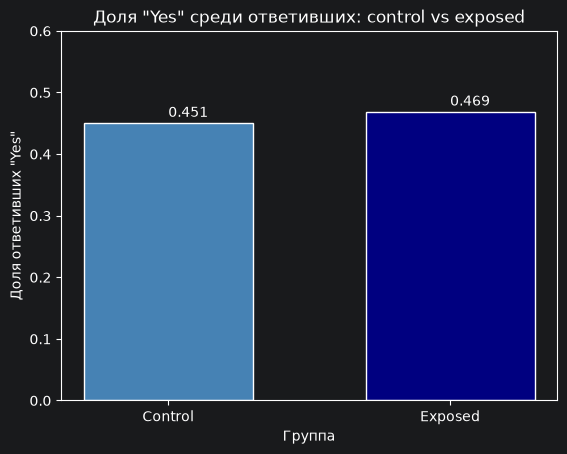

In [141]:
categories = ['Control',
              "Exposed"]
values = [
    proportion_yes_control,
    proportion_yes_exposed
]
plt.title('Доля "Yes" среди ответивших: control vs exposed')
plt.xlabel('Группа')
plt.ylabel('Доля ответивших "Yes"')
plt.bar(categories, values,
        color=['steelblue', 'navy'],
        width=0.6,
        edgecolor='white')
plt.ylim(0, 0.6)

for i, p in enumerate(values):
    plt.text(i, p+0.01, round(p, 3))


plt.show()


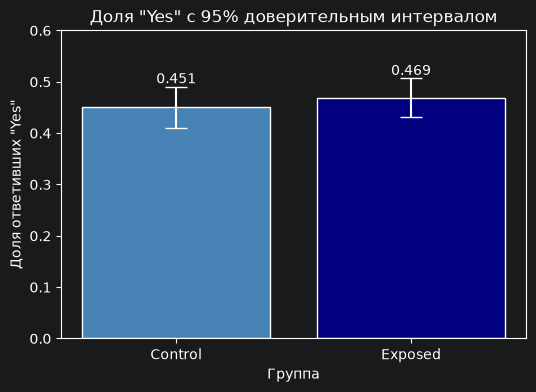

In [140]:
se_control = (proportion_yes_control * (1-proportion_yes_control) / answered_control)**0.5
se_exposed = (proportion_yes_exposed * (1-proportion_yes_exposed) / answered_exposed)**0.5

ci_control = Z_ALPHA * se_control
ci_exposed = Z_ALPHA * se_exposed

groups = ['Control', 'Exposed']
proportions = [
    proportion_yes_control, proportion_yes_exposed]
errors = [ci_control, ci_exposed]

figure, axis = plt.subplots(figsize=(6,4))

axis.bar(
    groups,
    proportions,
    yerr=errors,
    ecolor='white',
    capsize=8,
    color=['steelblue', 'navy'],
    edgecolor='white'
)

axis.set_ylabel('Доля ответивших "Yes"')
axis.set_xlabel('Группа')
axis.set_title('Доля "Yes" с 95% доверительным интервалом')

axis.set_ylim(0, 0.6)

for i, p in enumerate(proportions):
    axis.text(i, p + errors[i], f'{round(p, 3)}', ha='center', va='bottom')

plt.show()